# Job Market Intelligence
## Exploratory Data Analysis (EDA)


## Project Overview

### Background
The data analytics job market includes several related roles, such as Data Analyst, Business Analyst, Data Engineer, and Data Scientist. Although these roles may share technical skills, their job demand, salary levels, and skill requirements can differ.

This project explores job postings to understand these differences and identify patterns that may help aspiring data professionals make more informed career decisions.

### Objectives
1. Examine the structure and quality of the job-posting dataset.
2. Explore job demand across job categories and countries.
3. Understand salary distributions and compare salary levels across roles.
4. Identify the most frequently requested skills for Data Analyst positions.
5. Explore how skill requirements differ across related data roles.

### Research Questions
- Which data-related job categories have the highest posting volume?
- Which countries contribute the most job postings?
- What are the typical annual and hourly salaries for Data Analyst positions?
- Which skills are most frequently requested for Data Analyst roles?
- How do skill requirements differ between Business Analyst, Data Analyst, Data Engineer, and Data Scientist roles?

### Analysis Scope
This notebook focuses on data understanding, data-quality checks, descriptive analysis, and exploratory visualizations. Formal hypothesis testing and pairwise statistical comparisons are conducted separately in `02_statistical_analysis.ipynb`.

### Important Context
The dataset represents job postings from 2023. It should be interpreted as a historical snapshot rather than a direct measurement of the current job market.

## 1. Data Sources and Structure

The analysis uses four relational tables stored in PostgreSQL:

| Table | Description |
|---|---|
| `job_postings_fact` | Job-posting records, including title, location, salary, schedule, and posting date |
| `company_dim` | Company information |
| `skills_dim` | Skill names and identifiers |
| `skills_job_dim` | Relationship between job postings and requested skills |

### Relationships

- `job_postings_fact.company_id` → `company_dim.company_id`
- `skills_job_dim.job_id` → `job_postings_fact.job_id`
- `skills_job_dim.skill_id` → `skills_dim.skill_id`

The dataset is analyzed through SQL queries executed from Python. The original database tables are not modified by this notebook.

## 2. Environment Setup

Import the libraries used throughout the analysis and establish a connection to the PostgreSQL database.

**Requirements:** Install the packages listed in the project's `requirements.txt` before running the notebook.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from dotenv import load_dotenv
from sqlalchemy import create_engine, URL, text

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

sns.set_theme(style="whitegrid", palette="deep")

In [2]:
# Locate the project root by searching for the .env file.
PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / ".env").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError(
            "Could not find .env. Open this notebook from inside the project folder."
        )
    PROJECT_ROOT = PROJECT_ROOT.parent

load_dotenv(PROJECT_ROOT / ".env")

required_env_vars = ["DB_USER", "DB_PASSWORD", "DB_HOST", "DB_PORT", "DB_NAME"]
missing_env_vars = [var for var in required_env_vars if not os.getenv(var)]

if missing_env_vars:
    raise EnvironmentError(
        f"Missing environment variables: {', '.join(missing_env_vars)}"
    )

db_url = URL.create(
    drivername="postgresql+psycopg2",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT")),
    database=os.getenv("DB_NAME"),
)

engine = create_engine(db_url)

with engine.connect() as connection:
    connection.execute(text("SELECT 1"))

print("Database connection successful.")
print(f"Project root: {PROJECT_ROOT}")

Database connection successful.
Project root: c:\Users\bilal\Desktop\ㅤ\Project\job_market_intelligence


## 3. Load Data

Load the main job-posting table and the supporting skill tables. Keeping the source tables separate makes it easier to inspect their structure and avoid unnecessary duplication during analysis.

In [3]:
query_jobs = '''
SELECT
    job_id,
    company_id,
    job_title,
    job_title_short,
    job_location,
    job_country,
    job_work_from_home,
    job_schedule_type,
    job_posted_date,
    salary_year_avg,
    salary_hour_avg
FROM job_postings_fact;
'''

query_skills = '''
SELECT
    skill_id,
    skills
FROM skills_dim;
'''

query_job_skills = '''
SELECT
    job_id,
    skill_id
FROM skills_job_dim;
'''

jobs_df = pd.read_sql(query_jobs, engine)
skills_df = pd.read_sql(query_skills, engine)
job_skills_df = pd.read_sql(query_job_skills, engine)

print(f"Job postings: {len(jobs_df):,}")
print(f"Skills: {len(skills_df):,}")
print(f"Job-skill relationships: {len(job_skills_df):,}")

Job postings: 787,686
Skills: 259
Job-skill relationships: 3,669,604


## 4. Initial Data Inspection

Review the dimensions, data types, sample records, and descriptive summaries before performing more detailed analysis.

In [4]:
display(jobs_df.head())
display(jobs_df.info())

,job_id,company_id,job_title,job_title_short,job_location,job_country,job_work_from_home,job_schedule_type,job_posted_date,salary_year_avg,salary_hour_avg
0,50429,43608,Data Scientist,Data Scientist,"Irvine, CA",United States,False,Full-time,2023-07-29 09:02:46,NaN,NaN
1,50457,1148,Data Scientist,Data Scientist,Anywhere,United States,True,Full-time and Temp work,2023-09-26 09:38:45,NaN,NaN
2,50478,43610,Junior Data Analyst,Data Analyst,"Cape Town, South Africa",South Africa,False,Full-time,2023-07-16 09:19:46,NaN,NaN
3,50491,43611,"Software Engineer, Data Science",Data Scientist,"Washington, DC",United States,False,Contractor,2023-12-14 09:34:33,NaN,NaN
4,50493,15534,Data Engineer,Data Engineer,"Düsseldorf, Germany",Germany,False,Full-time,2023-09-26 09:15:31,NaN,NaN


<class 'pandas.DataFrame'>
RangeIndex: 787686 entries, 0 to 787685
Data columns (total 11 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   job_id              787686 non-null  int64         
 1   company_id          787686 non-null  int64         
 2   job_title           787685 non-null  str           
 3   job_title_short     787686 non-null  str           
 4   job_location        786633 non-null  str           
 5   job_country         787634 non-null  str           
 6   job_work_from_home  787686 non-null  bool          
 7   job_schedule_type   774981 non-null  str           
 8   job_posted_date     787686 non-null  datetime64[us]
 9   salary_year_avg     22034 non-null   float64       
 10  salary_hour_avg     10665 non-null   float64       
dtypes: bool(1), datetime64[us](1), float64(2), int64(2), str(5)
memory usage: 60.8 MB


None

In [5]:
print("Job postings shape:", jobs_df.shape)
print("Skills shape:", skills_df.shape)
print("Job-skill relationships shape:", job_skills_df.shape)

display(jobs_df.describe(include="all").T)

Job postings shape: (787686, 11)
Skills shape: (259, 2)
Job-skill relationships shape: (3669604, 2)


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
job_id,"787,686.00",NaN,NaN,NaN,"751,460.86",0.00,"278,515.75","672,703.50","1,185,031.25","1,826,678.00","530,243.42"
company_id,"787,686.00",NaN,NaN,NaN,"97,968.55",0.00,"3,332.00","23,326.00","112,107.00","787,681.00","160,374.99"
job_title,787685,235062,Data Engineer,54030,NaN,NaN,NaN,NaN,NaN,NaN,NaN
job_title_short,787686,10,Data Analyst,196593,NaN,NaN,NaN,NaN,NaN,NaN,NaN
job_location,786633,17222,Anywhere,69606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
job_country,787634,160,United States,206943,NaN,NaN,NaN,NaN,NaN,NaN,NaN
job_work_from_home,787686,2,False,718080,NaN,NaN,NaN,NaN,NaN,NaN,NaN
job_schedule_type,774981,47,Full-time,703597,NaN,NaN,NaN,NaN,NaN,NaN,NaN
job_posted_date,787686,NaN,NaN,NaN,2023-06-25 00:16:36.784759,2022-12-31 06:00:59,2023-03-19 07:31:14.500000,2023-06-28 12:35:55,2023-09-26 14:19:36,2023-12-31 06:12:38,NaN
salary_year_avg,"22,034.00",NaN,NaN,NaN,"123,268.82","15,000.00","90,000.00","115,000.00","150,000.00","960,000.00","48,271.06"


## 5. Data Quality Assessment

This section checks missing values, duplicate identifiers, and relationship integrity. Missing salary values are expected in job-posting data and should not be replaced with zero, because zero would represent an actual reported salary rather than an unavailable value.

In [6]:
# Missing values in the main job-posting table
missing_summary = (
    jobs_df.isna()
    .sum()
    .to_frame("missing_count")
    .assign(
        missing_percentage=lambda df: (
            df["missing_count"] / len(jobs_df) * 100
        )
    )
    .sort_values("missing_count", ascending=False)
)

display(missing_summary)

,missing_count,missing_percentage
salary_hour_avg,777021,98.65
salary_year_avg,765652,97.20
job_schedule_type,12705,1.61
job_location,1053,0.13
job_country,52,0.01
job_title,1,0.00
job_id,0,0.00
company_id,0,0.00
job_title_short,0,0.00
job_work_from_home,0,0.00


In [7]:
# Duplicate primary-key checks
duplicate_checks = pd.Series({
    "job_postings_fact duplicate job_id": jobs_df["job_id"].duplicated().sum(),
    "skills_dim duplicate skill_id": skills_df["skill_id"].duplicated().sum(),
})

display(duplicate_checks.to_frame("duplicate_count"))

,duplicate_count
job_postings_fact duplicate job_id,0
skills_dim duplicate skill_id,0


In [8]:
# Referential-integrity checks
orphan_company_ids = (
    jobs_df.loc[
        jobs_df["company_id"].notna() &
        ~jobs_df["company_id"].isin(
            pd.read_sql("SELECT company_id FROM company_dim", engine)["company_id"]
        ),
        "company_id"
    ].nunique()
)

orphan_job_ids = (
    job_skills_df.loc[
        ~job_skills_df["job_id"].isin(jobs_df["job_id"]),
        "job_id"
    ].nunique()
)

orphan_skill_ids = (
    job_skills_df.loc[
        ~job_skills_df["skill_id"].isin(skills_df["skill_id"]),
        "skill_id"
    ].nunique()
)

integrity_summary = pd.Series({
    "Orphan company IDs": orphan_company_ids,
    "Orphan job IDs in skills_job_dim": orphan_job_ids,
    "Orphan skill IDs in skills_job_dim": orphan_skill_ids,
})

display(integrity_summary.to_frame("orphan_count"))

,orphan_count
Orphan company IDs,0
Orphan job IDs in skills_job_dim,0
Orphan skill IDs in skills_job_dim,0


### 6.1 Salary Data Availability

Salary information is not available for every posting. The following summary separates annual and hourly salary coverage.

In [9]:
salary_coverage = pd.DataFrame({
    "salary_type": ["Annual salary", "Hourly salary"],
    "available_records": [
        jobs_df["salary_year_avg"].notna().sum(),
        jobs_df["salary_hour_avg"].notna().sum()
    ]
})

salary_coverage["percentage_of_postings"] = (
    salary_coverage["available_records"] / len(jobs_df) * 100
)

display(salary_coverage)

,salary_type,available_records,percentage_of_postings
0,Annual salary,22034,2.80
1,Hourly salary,10665,1.35


### 6.2 Salary Reporting Rate

A large proportion of postings do not disclose salary information. Salary analysis in later sections therefore uses only records with the corresponding salary field available. Annual and hourly salaries are analyzed separately and are not directly combined.

## 7. Job Market Demand

This section explores posting volume by job category, country, and work arrangement. Counts describe the number of records in the dataset, not the number of unique people employed.

### 7.1 Job Demand by Category

In [10]:
category_demand = (
    jobs_df["job_title_short"]
    .value_counts(dropna=False)
    .rename_axis("job_category")
    .reset_index(name="posting_count")
)

display(category_demand.head(15))

,job_category,posting_count
0,Data Analyst,196593
1,Data Engineer,186679
2,Data Scientist,172726
3,Business Analyst,49160
4,Software Engineer,45019
5,Senior Data Engineer,44692
6,Senior Data Scientist,37076
7,Senior Data Analyst,29289
8,Machine Learning Engineer,14106
9,Cloud Engineer,12346


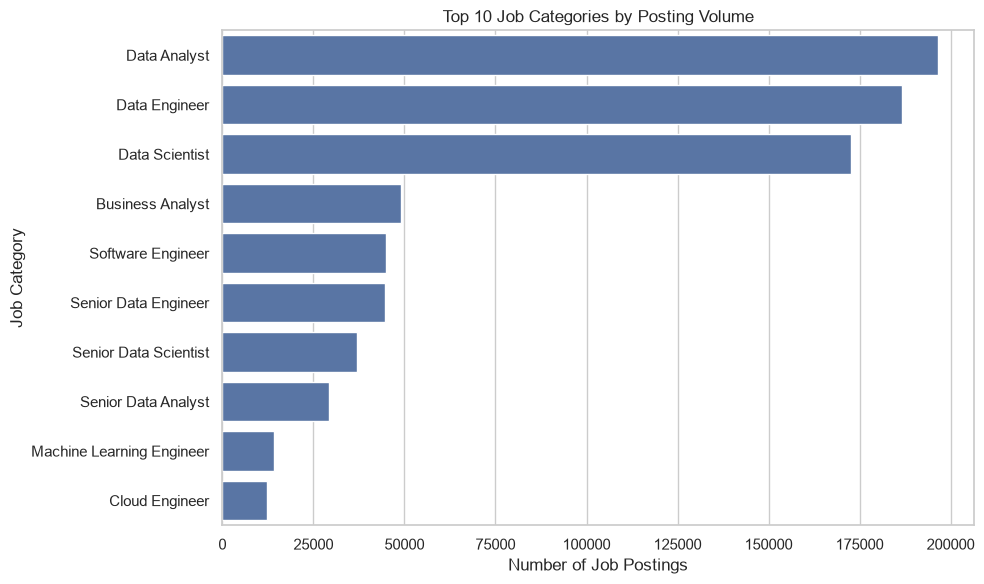

In [11]:
top_categories = category_demand.dropna().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_categories,
    x="posting_count",
    y="job_category"
)
plt.title("Top 10 Job Categories by Posting Volume")
plt.xlabel("Number of Job Postings")
plt.ylabel("Job Category")
plt.tight_layout()
plt.show()

### 7.2 Job Demand by Country

Country-level counts provide a broad view of the geographic distribution of postings. Country and location fields may contain inconsistencies, so geographic results should be interpreted cautiously.

In [12]:
country_demand = (
    jobs_df["job_country"]
    .value_counts(dropna=False)
    .rename_axis("country")
    .reset_index(name="posting_count")
)

display(country_demand.head(15))

,country,posting_count
0,United States,206943
1,India,51197
2,United Kingdom,40439
3,France,40028
4,Germany,27782
5,Spain,25123
6,Singapore,23702
7,Sudan,21519
8,Netherlands,20673
9,Italy,17073


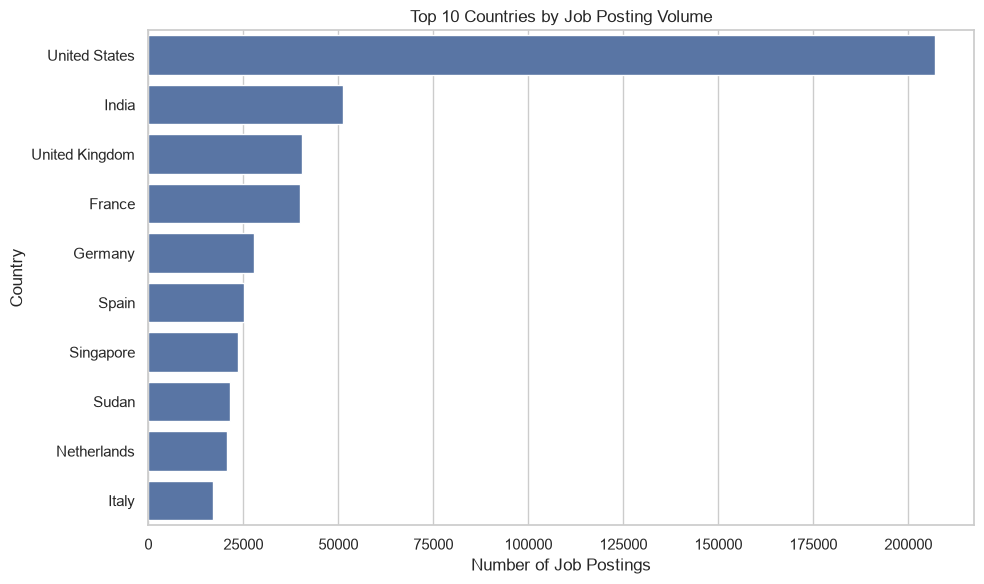

In [13]:
top_countries = country_demand.dropna().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_countries,
    x="posting_count",
    y="country"
)
plt.title("Top 10 Countries by Job Posting Volume")
plt.xlabel("Number of Job Postings")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

### 7.3 Work Arrangement

Explore the distribution of remote and non-remote job postings using the `job_work_from_home` field.

In [14]:
remote_distribution = (
    jobs_df["job_work_from_home"]
    .value_counts(dropna=False)
    .rename_axis("work_from_home")
    .reset_index(name="posting_count")
)

display(remote_distribution)

,work_from_home,posting_count
0,False,718080
1,True,69606


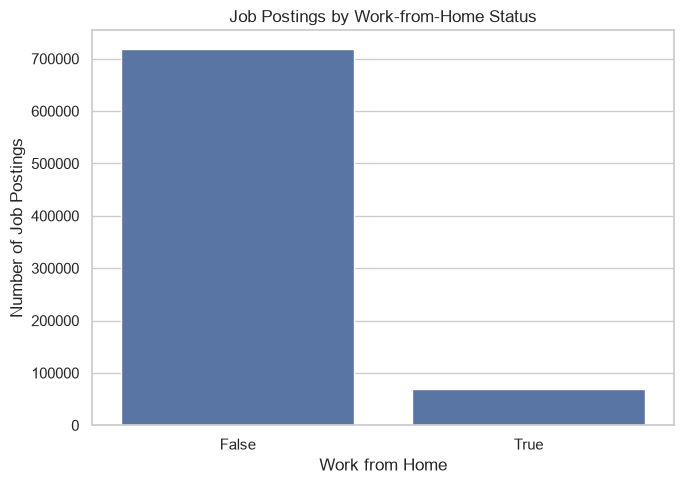

In [15]:
plt.figure(figsize=(7, 5))
sns.barplot(
    data=remote_distribution.astype({"work_from_home": str}),
    x="work_from_home",
    y="posting_count"
)
plt.title("Job Postings by Work-from-Home Status")
plt.xlabel("Work from Home")
plt.ylabel("Number of Job Postings")
plt.tight_layout()
plt.show()

### 7.4 Employment Schedule

Review the most common employment schedule types across all postings.

In [16]:
schedule_distribution = (
    jobs_df["job_schedule_type"]
    .value_counts(dropna=False)
    .rename_axis("schedule_type")
    .reset_index(name="posting_count")
)

display(schedule_distribution.head(15))

,schedule_type,posting_count
0,Full-time,703597
1,Contractor,34827
2,NaN,12705
3,Internship,8752
4,Part-time,7888
5,Full-time and Part-time,6288
6,Full-time and Temp work,2622
7,Full-time and Internship,2336
8,Full-time and Contractor,2291
9,Contractor and Temp work,2281


## 8. Data Analyst Role Analysis

The project places particular emphasis on Data Analyst positions. This section narrows the dataset to Data Analyst postings and explores their demand, location, salary, and schedule characteristics.

In [17]:
da_df = jobs_df.loc[
    jobs_df["job_title_short"].eq("Data Analyst")
].copy()

print(f"Data Analyst postings: {len(da_df):,}")
display(da_df.head())

Data Analyst postings: 196,593


,job_id,company_id,job_title,job_title_short,job_location,job_country,job_work_from_home,job_schedule_type,job_posted_date,salary_year_avg,salary_hour_avg
2,50478,43610,Junior Data Analyst,Data Analyst,"Cape Town, South Africa",South Africa,False,Full-time,2023-07-16 09:19:46,NaN,NaN
6,50521,1640,Fraud Data Analyst,Data Analyst,"Vienna, Austria",Austria,False,Full-time,2023-02-15 10:16:12,NaN,NaN
12,50602,13252,Data Analyst & Dashboard Developer,Data Analyst,Anywhere,United States,True,Full-time,2023-05-17 08:59:58,"85,000.00",NaN
14,50644,43622,BI Engineer/Data analyst,Data Analyst,"Antwerp, Belgium",Belgium,False,Full-time,2023-02-25 09:10:46,NaN,NaN
23,50805,189,Data Analyst II,Data Analyst,"Chamblee, GA",United States,False,Full-time,2023-08-01 09:43:14,NaN,NaN


### 8.1 Data Analyst Job Postings Over Time

The monthly trend is calculated from the posting date. This requires a valid date field and excludes records with missing posting dates.

In [18]:
da_df["job_posted_date"] = pd.to_datetime(
    da_df["job_posted_date"],
    errors="coerce"
)

da_monthly = (
    da_df.dropna(subset=["job_posted_date"])
    .assign(month=lambda df: df["job_posted_date"].dt.to_period("M").dt.to_timestamp())
    .groupby("month")
    .size()
    .reset_index(name="posting_count")
)

display(da_monthly.head())

,month,posting_count
0,2022-12-01,485
1,2023-01-01,23697
2,2023-02-01,16479
3,2023-03-01,16342
4,2023-04-01,15499


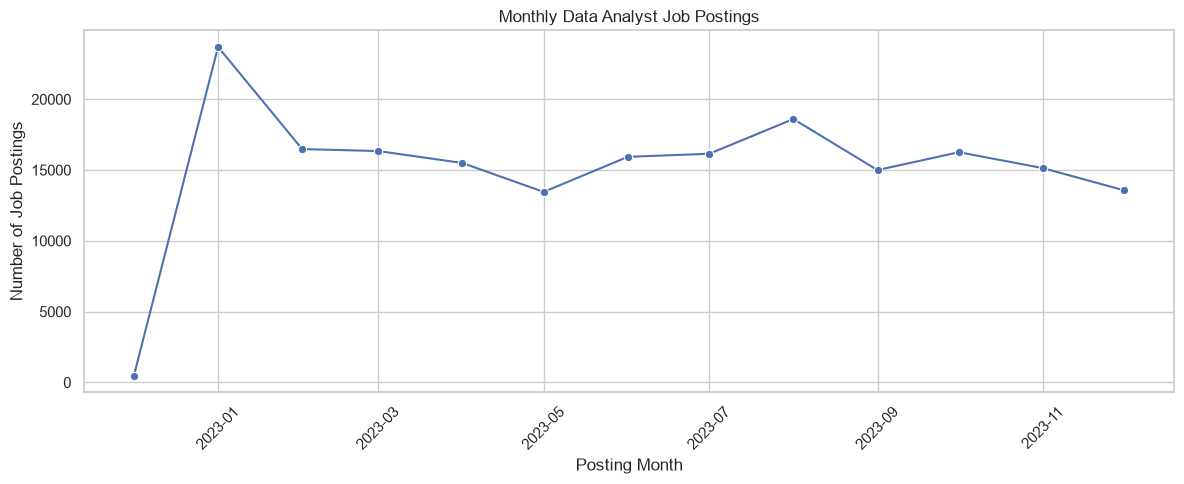

In [19]:
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=da_monthly,
    x="month",
    y="posting_count",
    marker="o"
)
plt.title("Monthly Data Analyst Job Postings")
plt.xlabel("Posting Month")
plt.ylabel("Number of Job Postings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 8.2 Data Analyst Employment Schedule

In [20]:
da_schedule = (
    da_df["job_schedule_type"]
    .value_counts(dropna=False)
    .rename_axis("schedule_type")
    .reset_index(name="posting_count")
)

display(da_schedule)

,schedule_type,posting_count
0,Full-time,169471
1,Contractor,10022
2,NaN,4617
3,Internship,3305
4,Part-time,3195
5,Full-time and Part-time,1583
6,Full-time and Temp work,864
7,Full-time and Internship,823
8,Temp work,768
9,Full-time and Contractor,641


## 9. Salary Exploration

Salary distributions are explored separately for annual and hourly compensation. Since salary values are available for only a subset of postings, each result should be interpreted together with its sample size.

Extreme values are not automatically removed. They may represent genuine high-paying roles, different seniority levels, or data-quality issues and should be investigated before exclusion.

### 9.1 Annual Salary by Job Category

In [21]:
annual_salary_df = jobs_df.dropna(
    subset=["salary_year_avg", "job_title_short"]
).copy()

annual_salary_summary = (
    annual_salary_df
    .groupby("job_title_short")["salary_year_avg"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
        maximum="max"
    )
    .sort_values("median", ascending=False)
)

display(annual_salary_summary)

,count,mean,median,std,minimum,q1,q3,maximum
job_title_short,,,,,,,,
Senior Data Scientist,1686,"154,050.03","155,000.00","50,865.05","45,000.00","125,000.00","173,000.00","890,000.00"
Senior Data Engineer,1594,"145,866.87","147,500.00","37,430.38","35,000.00","125,000.00","166,761.00","425,000.00"
Data Scientist,5926,"135,929.48","127,500.00","52,247.65","27,000.00","100,000.00","158,857.50","960,000.00"
Data Engineer,4509,"130,266.87","125,000.00","42,503.07","15,000.00","100,000.00","147,500.00","525,000.00"
Senior Data Analyst,1132,"114,104.05","111,175.00","34,100.26","30,000.00","92,500.00","125,000.00","425,000.00"
Machine Learning Engineer,573,"126,785.91","106,000.00","53,988.99","30,000.00","80,850.00","166,000.00","325,000.00"
Software Engineer,469,"112,777.64","99,150.00","50,733.22","28,000.00","79,200.00","147,500.00","375,000.00"
Cloud Engineer,65,"111,268.45","90,000.00","50,514.35","42,000.00","79,200.00","136,000.00","280,000.00"
Data Analyst,5463,"93,875.79","90,000.00","34,086.67","25,000.00","70,000.00","111,175.00","650,000.00"


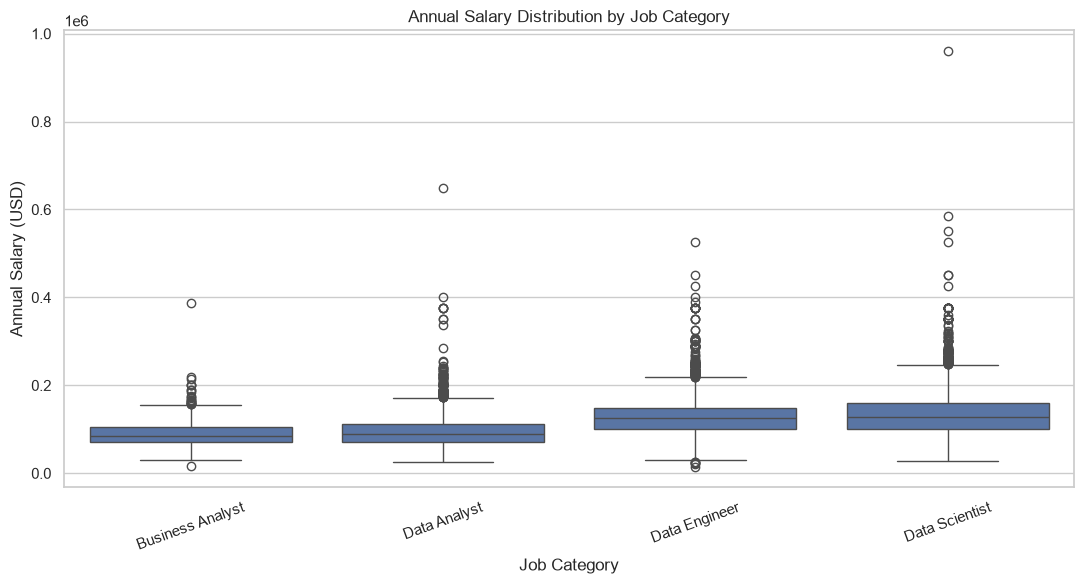

In [22]:
selected_categories = [
    "Business Analyst",
    "Data Analyst",
    "Data Engineer",
    "Data Scientist"
]

annual_selected = annual_salary_df[
    annual_salary_df["job_title_short"].isin(selected_categories)
]

plt.figure(figsize=(11, 6))
sns.boxplot(
    data=annual_selected,
    x="job_title_short",
    y="salary_year_avg",
    order=selected_categories
)
plt.title("Annual Salary Distribution by Job Category")
plt.xlabel("Job Category")
plt.ylabel("Annual Salary (USD)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### 9.2 Data Analyst Annual Salary Distribution

In [23]:
da_annual_salary = da_df["salary_year_avg"].dropna()

print(f"Annual salary records: {len(da_annual_salary):,}")
print(f"Mean: ${da_annual_salary.mean():,.2f}")
print(f"Median: ${da_annual_salary.median():,.2f}")
print(f"Standard deviation: ${da_annual_salary.std():,.2f}")

Annual salary records: 5,463
Mean: $93,875.79
Median: $90,000.00
Standard deviation: $34,086.67


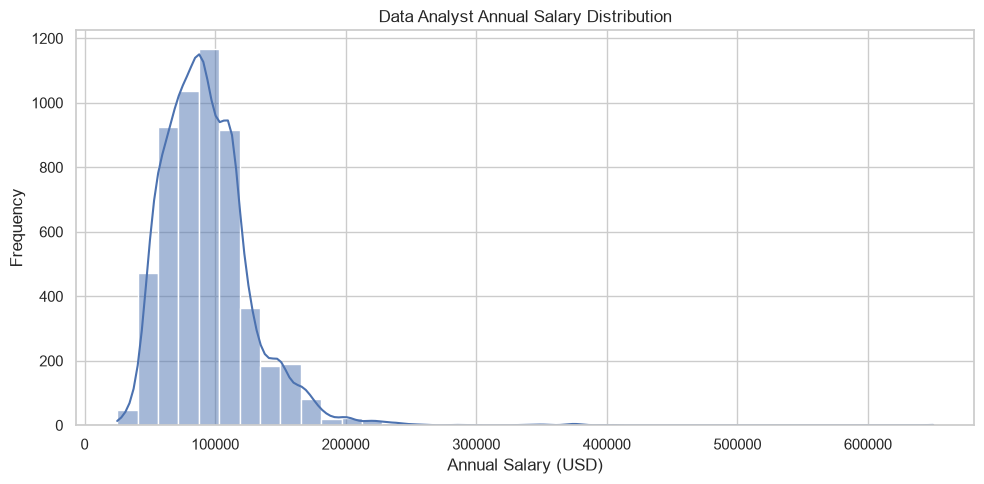

In [24]:
plt.figure(figsize=(10, 5))
sns.histplot(da_annual_salary, bins=40, kde=True)
plt.title("Data Analyst Annual Salary Distribution")
plt.xlabel("Annual Salary (USD)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### 9.3 Data Analyst Hourly Salary Distribution

In [25]:
da_hourly_salary = da_df["salary_hour_avg"].dropna()

print(f"Hourly salary records: {len(da_hourly_salary):,}")
print(f"Mean: ${da_hourly_salary.mean():,.2f}")
print(f"Median: ${da_hourly_salary.median():,.2f}")
print(f"Standard deviation: ${da_hourly_salary.std():,.2f}")

Hourly salary records: 4,135
Mean: $38.15
Median: $32.72
Standard deviation: $18.93


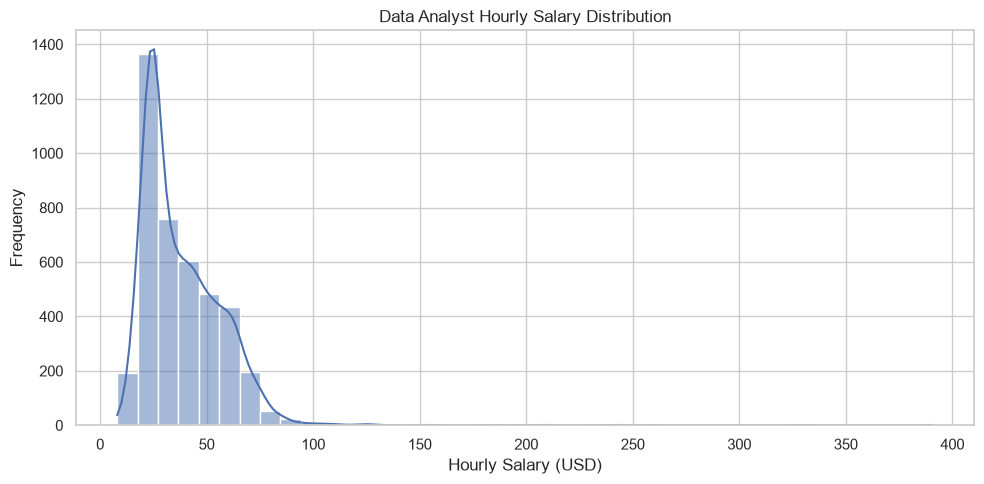

In [26]:
plt.figure(figsize=(10, 5))
sns.histplot(da_hourly_salary, bins=40, kde=True)
plt.title("Data Analyst Hourly Salary Distribution")
plt.xlabel("Hourly Salary (USD)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## 10. Skill Demand Analysis

Skill demand is calculated from the relationship between job postings and skills. A posting can require multiple skills, so skill percentages are not expected to sum to 100%.

Skill names are normalized with lowercase and whitespace trimming to reduce inconsistencies in text formatting.

In [27]:
query_da_skills = '''
SELECT
    LOWER(TRIM(sd.skills)) AS skill,
    COUNT(DISTINCT jp.job_id) AS job_count
FROM job_postings_fact AS jp
JOIN skills_job_dim AS sj
    ON jp.job_id = sj.job_id
JOIN skills_dim AS sd
    ON sj.skill_id = sd.skill_id
WHERE jp.job_title_short = 'Data Analyst'
GROUP BY LOWER(TRIM(sd.skills))
ORDER BY job_count DESC;
'''

da_skills = pd.read_sql(query_da_skills, engine)
da_skills["percentage_of_da_postings"] = (
    da_skills["job_count"] / len(da_df) * 100
)

display(da_skills.head(20))

,skill,job_count,percentage_of_da_postings
0,sql,92628,47.12
1,excel,67031,34.10
2,python,57326,29.16
3,tableau,46554,23.68
4,power bi,39468,20.08
5,r,30075,15.30
6,sas,14034,7.14
7,powerpoint,13848,7.04
8,word,13591,6.91
9,sap,11297,5.75


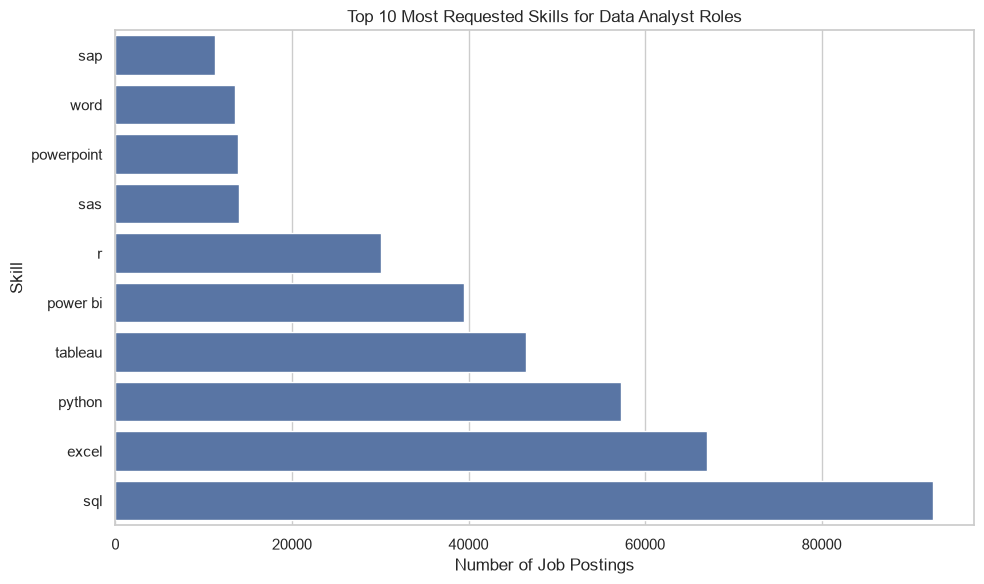

In [28]:
top_da_skills = da_skills.head(10).sort_values("job_count")

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_da_skills,
    x="job_count",
    y="skill"
)
plt.title("Top 10 Most Requested Skills for Data Analyst Roles")
plt.xlabel("Number of Job Postings")
plt.ylabel("Skill")
plt.tight_layout()
plt.show()

### 10.1 Skill Requirements Across Job Categories

Compare the percentage of postings requesting selected skills across Business Analyst, Data Analyst, Data Engineer, and Data Scientist roles. The denominator is the total number of postings in each category.

In [29]:
query_category_skills = '''
WITH category_totals AS (
    SELECT
        job_title_short,
        COUNT(DISTINCT job_id) AS total_jobs
    FROM job_postings_fact
    WHERE job_title_short IN (
        'Business Analyst',
        'Data Analyst',
        'Data Engineer',
        'Data Scientist'
    )
    GROUP BY job_title_short
),
skill_counts AS (
    SELECT
        jp.job_title_short,
        LOWER(TRIM(sd.skills)) AS skill,
        COUNT(DISTINCT jp.job_id) AS job_count
    FROM job_postings_fact AS jp
    JOIN skills_job_dim AS sj
        ON jp.job_id = sj.job_id
    JOIN skills_dim AS sd
        ON sj.skill_id = sd.skill_id
    WHERE jp.job_title_short IN (
        'Business Analyst',
        'Data Analyst',
        'Data Engineer',
        'Data Scientist'
    )
    GROUP BY jp.job_title_short, LOWER(TRIM(sd.skills))
)
SELECT
    sc.job_title_short,
    sc.skill,
    sc.job_count,
    ct.total_jobs,
    ROUND(100.0 * sc.job_count / ct.total_jobs, 2) AS percentage
FROM skill_counts AS sc
JOIN category_totals AS ct
    ON sc.job_title_short = ct.job_title_short
WHERE sc.skill IN (
    'aws', 'azure', 'excel', 'power bi', 'python',
    'r', 'spark', 'sql', 'tableau', 'sas'
)
ORDER BY sc.skill, sc.job_title_short;
'''

category_skills = pd.read_sql(query_category_skills, engine)
display(category_skills.head(20))

,job_title_short,skill,job_count,total_jobs,percentage
0,Business Analyst,aws,1823,49160,3.71
1,Data Analyst,aws,9063,196593,4.61
2,Data Engineer,aws,62174,186679,33.31
3,Data Scientist,aws,26311,172726,15.23
4,Business Analyst,azure,2538,49160,5.16
5,Data Analyst,azure,10942,196593,5.57
6,Data Engineer,azure,60823,186679,32.58
7,Data Scientist,azure,21698,172726,12.56
8,Business Analyst,excel,17134,49160,34.85
9,Data Analyst,excel,67031,196593,34.10


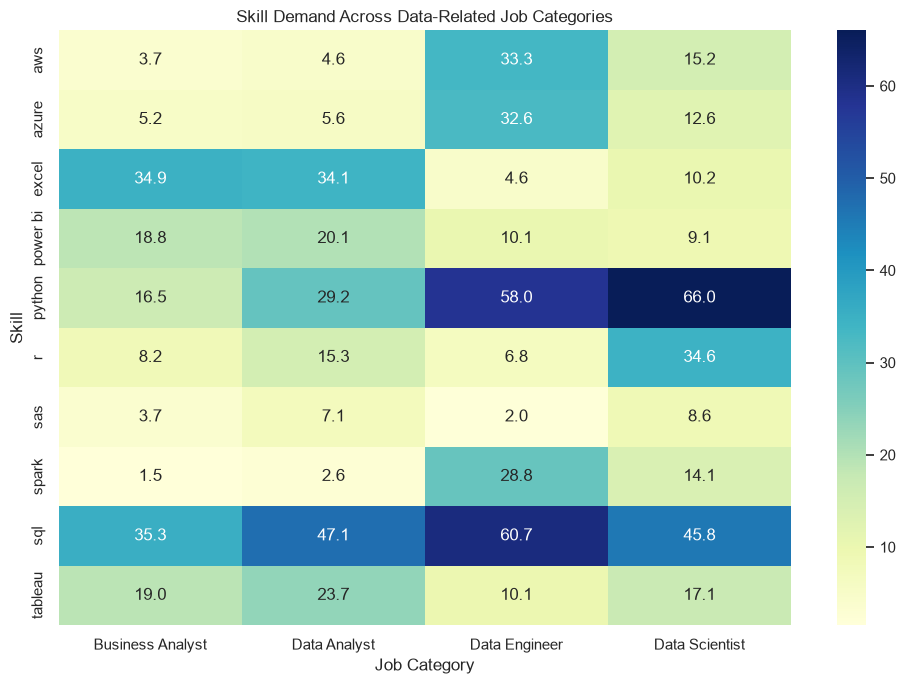

In [30]:
skill_heatmap = category_skills.pivot(
    index="skill",
    columns="job_title_short",
    values="percentage"
)

plt.figure(figsize=(10, 7))
sns.heatmap(
    skill_heatmap,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)
plt.title("Skill Demand Across Data-Related Job Categories")
plt.xlabel("Job Category")
plt.ylabel("Skill")
plt.tight_layout()
plt.show()

## 11. Key Findings

Use this section to record the most important observations from the executed analysis. The figures below are based on the current project analysis and should be checked against the latest notebook outputs if the underlying database changes.

### Job Market Demand
- The dataset contains approximately **788K job postings**.
- Data Analyst postings account for approximately **197K records**.
- The United States has the largest number of postings in the country-level breakdown.
- Full-time roles represent the majority of Data Analyst postings with a known schedule type.

### Salary
- Data Analyst annual salary median: approximately **$90,000**.
- Data Analyst annual salary mean: approximately **$93,876**.
- Data Analyst hourly salary median: approximately **$32.72**.
- Salary information is missing for most job postings, so salary findings represent only records with reported values.

### Skills
- SQL is the most frequently requested skill for Data Analyst roles.
- Excel, Python, Tableau, and Power BI are also among the most frequently requested skills.
- Skill requirements vary across job categories: Python is especially prominent in Data Scientist and Data Engineer postings, while Excel is more prominent in Business Analyst and Data Analyst postings.

### Interpretation Notes
- These are descriptive patterns, not causal relationships.
- A job posting may contain multiple skill requirements.
- Geographic anomalies in the source data require caution when interpreting country-level results.
- The dataset represents 2023 postings, not current hiring demand.

## 12. Limitations and Next Steps

### Limitations
1. **Historical snapshot:** The dataset covers job postings from 2023 and may not reflect current labor-market conditions.
2. **Incomplete salary information:** Most postings do not provide annual or hourly salary values.
3. **Geographic inconsistencies:** Some country and location records appear inconsistent, which may affect geographic summaries.
4. **Multiple skills per posting:** Skill counts and percentages are not mutually exclusive.
5. **Uncontrolled factors:** Salary differences may reflect location, experience, seniority, company, and job responsibilities.

### Next Steps
- Use `02_statistical_analysis.ipynb` to test salary-distribution differences across selected job categories.
- Use SQL views and Power BI to present the main findings in an interactive dashboard.
- Revisit geographic and salary data-quality issues if the project is extended.
